# Solar Filament Segmentation Challenge 2026 — full pipeline

This notebook reproduces the final submission end to end on a CPU. It loads the saved weights in `weights/` and does **not** retrain.
A plain-language explanation of every step is in `docs/HOW_IT_WORKS.md`.

1. Data discovery
2. Pre-processing: solar disk detection and limb-darkening flattening
3. **Method A (classical baseline):** black-hat plus darkness map → adaptive hysteresis threshold → half-contrast boundary → sunspot filter
4. **Method B (final model): U-Net with an ImageNet-pretrained ResNet-50 encoder** (32.5M parameters, `segmentation-models-pytorch`), trained for 240 min on a Kaggle T4 GPU on flattened 1024 px discs (512 px crops, BCE + Dice loss); prediction averages three views (original and two flips). The weights are stored in two parts (`weights/unet_r50.pt.part1/.part2`, GitHub's file-size limit) and joined automatically on loading.
5. Instance formation: probability ≥ 0.7, small specks and holes removed, fragments closer than 12 px joined, instances < 400 px dropped (settings chosen for dataset-level Panoptic Quality on all 106 validation files)
6. Local evaluation: PQ, SQ, RQ, Dice/IoU distributions, one-to-many and many-to-one counts
7. Submission CSV (COCO RLE)

**Results** on 106 held-out validation files (168 annotator entries): final ResNet-50 U-Net PQ **0.419**; previous ResNet-34 U-Net 0.411 (Kaggle public 0.33); small CPU-trained U-Net 0.338 (0.27); classical 0.262 (0.21). Section 6 re-scores the first 40 validation entries to save time; the full 106-file results are computed by `scripts/eval_val.py` and loaded from `weights/eval_*.json`.

Training is done by `kaggle_train.ipynb` (GPU) or `scripts/run.py train` (see README). The flag `RETRAIN` re-runs it here with the same settings (a GPU is needed for the 240-minute budget to give the same model). Earlier models are kept for comparison: `weights/unet_r34.pt` (ResNet-34) and `weights/unet_cpu.pt` (small U-Net trained on the laptop CPU).

In [1]:
import os, sys, json, time
import numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("src"))
from filseg import *
from filseg import pipeline
from dataclasses import asdict

DATA       = "data"                                   # competition folder
TRAIN_JSON = "data/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TRAIN_DIR  = "data/MAGFiLO_1.0_Kaggle_2026/train/train_images"
TEST_DIR   = "data/MAGFiLO_1.0_Kaggle_2026/test/test_images"
WEIGHTS    = "weights/unet_r50.pt"                    # final model; stored as unet_r50.pt.part1 + .part2 (GitHub limit)
PP_UNET    = "weights/postprocess_unet_r50.json"      # its tuned threshold / linking / size settings
HAVE_UNET  = os.path.exists(WEIGHTS) or os.path.exists(WEIGHTS + ".part1")
METHOD     = "unet" if HAVE_UNET else "classical"
RETRAIN    = False
print("method:", METHOD)

method: unet


## 1. Data

In [2]:
_ = discover(DATA)

json : ['data\\MAGFiLO_1.0_Kaggle_2026\\train\\MAGFiLO_1.0_Annotations_kaggle2026_train.json', 'data\\_fpstudy\\summary.json']
csv : ['data\\_sem_classical\\smooth_study.csv']
dirs : {'data\\MAGFiLO_1.0_Kaggle_2026\\test\\test_images': 180, 'data\\MAGFiLO_1.0_Kaggle_2026\\train\\train_images': 707}


In [3]:
coco = CocoSet(TRAIN_JSON, TRAIN_DIR)
sys.path.insert(0, os.path.abspath("scripts"))
from run import split_ids          # split by image file (some images have several annotators)
train_ids, val_ids = split_ids(coco)
print(len(train_ids), "train /", len(val_ids), "val")

MAGFiLO_1.0_Annotations_kaggle2026_train.json: 1154 images on disk, 8199 filament annotations
986 train / 168 val


## 2. Pre-processing

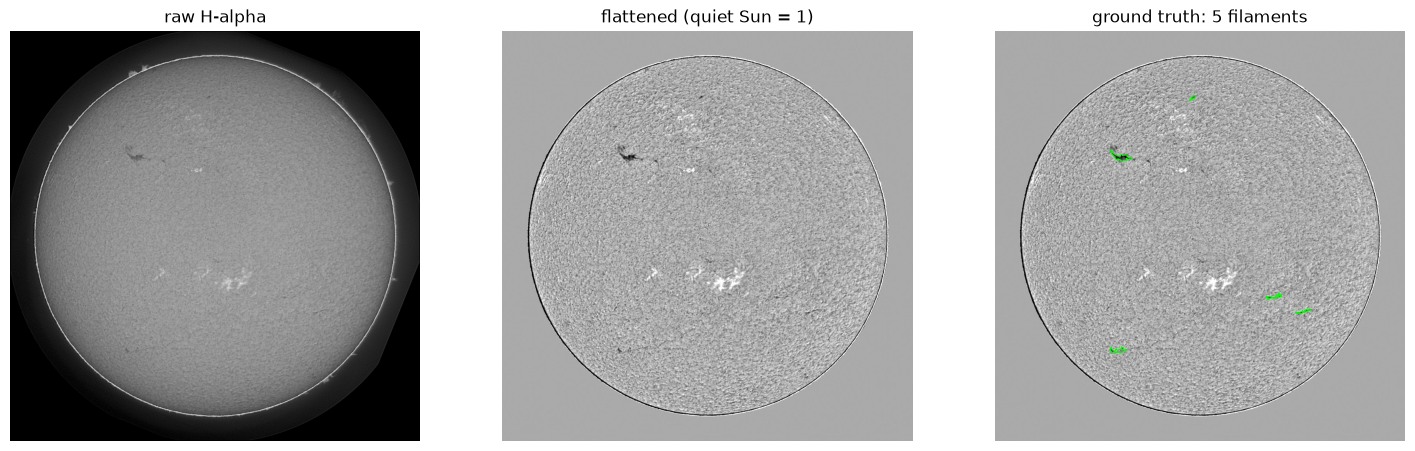

In [4]:
i = val_ids[0]
img = read_image(coco.path_of[i]); flat, disk = preprocess(img)
gt = coco.instance_masks(i)
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("raw H-alpha")
ax[1].imshow(flat, cmap="gray", vmin=0.6, vmax=1.2); ax[1].set_title("flattened (quiet Sun = 1)")
ax[2].imshow(flat, cmap="gray", vmin=0.6, vmax=1.2)
for m in gt: ax[2].contour(m, [0.5], colors="lime", linewidths=0.6)
ax[2].set_title(f"ground truth: {len(gt)} filaments")
for a in ax: a.axis("off")

## 3. Method A — classical

In [5]:
cp = ClassicalParams(**json.load(open("weights/classical_params.json"))) if os.path.exists("weights/classical_params.json") else ClassicalParams()
pp_c = PostParams(**json.load(open("weights/postprocess_classical.json"))) if os.path.exists("weights/postprocess_classical.json") else PostParams()
print(cp); print(pp_c)
res_c, scores_c = pipeline.evaluate(coco, val_ids[:40], "classical", pp=pp_c, cp=cp)

ClassicalParams(work_size=1024, smooth_sigma=1.2, blackhat_size=31, k_low=2.0, k_high=5.5, limb_shrink=0.04, sunspot_max_intensity=0.55, sunspot_max_ecc=0.85, min_area=40, edge_frac=0.35)
PostParams(prob_threshold=0.5, min_fragment=60, hole_size=200, link_radius=20, min_instance=400, work_size=1024, min_dark=0.1, min_elong=1.5, max_rho=0.94, grow=1, tta='flip')


{'PQ_dataset': np.float64(0.2709), 'PQ_mean_per_image': 0.2631, 'SQ': np.float64(0.6361), 'RQ': 0.4259, 'TP': 102, 'FP': 97, 'FN': 178, 'mean_IoU_matched': 0.6361, 'mean_Dice_matched': 0.7747, 'one_to_many': 4, 'many_to_one': 1, 'sec_per_image': 2.2094}


## 4. Method B — U-Net

In [6]:
if RETRAIN:   # same settings as the Kaggle GPU run (kaggle_train.ipynb, Version 4, GPU 1: 240 min on a T4)
    from filseg import unet
    tr = unet.build_cache(coco, train_ids, "data/_cache1024")
    va = unet.build_cache(coco, val_ids[:20], "data/_cache1024")
    cfg = unet.TrainConfig(arch="smp", encoder="resnet50", crop=512, batch=8, lr=5e-4, time_budget_min=240)
    unet.train(tr, va, cfg, WEIGHTS)
    HAVE_UNET = True
model = None
if HAVE_UNET:
    from filseg import unet
    model = unet.load_model(WEIGHTS)   # joins the two parts, rebuilds the network, loads the trained weights (no download)
    print(type(model).__name__, f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")
    pp_u = PostParams(**json.load(open(PP_UNET)))
    print(pp_u)
    res_u, scores_u = pipeline.evaluate(coco, val_ids[:40], "unet", model=model, pp=pp_u)

Unet 32.51M parameters
PostParams(prob_threshold=0.7, min_fragment=60, hole_size=200, link_radius=12, min_instance=400, work_size=1024, min_dark=0.0, min_elong=0.0, max_rho=9.0, grow=0, tta='flip')


{'PQ_dataset': np.float64(0.4051), 'PQ_mean_per_image': 0.3587, 'SQ': np.float64(0.6692), 'RQ': 0.6054, 'TP': 168, 'FP': 107, 'FN': 112, 'mean_IoU_matched': 0.6692, 'mean_Dice_matched': 0.7983, 'one_to_many': 10, 'many_to_one': 6, 'sec_per_image': 17.8939}


## 5–6. Comparison and qualitative results

In [7]:
import pandas as pd
rows = {"classical": res_c}
if model is not None: rows["unet"] = res_u
display(pd.DataFrame(rows).T)

,PQ_dataset,PQ_mean_per_image,SQ,RQ,TP,FP,FN,mean_IoU_matched,mean_Dice_matched,one_to_many,many_to_one,sec_per_image
classical,0.270895,0.263104,0.636073,0.425887,102.0,97.0,178.0,0.636073,0.774729,4.0,1.0,2.209429
unet,0.405120,0.358663,0.669172,0.605405,168.0,107.0,112.0,0.669172,0.798339,10.0,6.0,17.893875


In [8]:
# Full held-out validation: 106 files, 168 annotator entries (computed by scripts/eval_val.py).
# org_* = the organisers' one-to-many / many-to-one counts (any overlap); sec_per_image = laptop CPU.
cols = ["PQ_dataset", "PQ_dataset_ci95", "SQ", "RQ", "TP", "FP", "FN", "mean_Dice_matched",
        "org_one_to_many_iou0", "org_many_to_one_iou0", "sec_per_image"]
full = {}
for tag, name in [("unet_r50", "U-Net ResNet-50 (final)"), ("unet_r34", "U-Net ResNet-34 (previous, public 0.33)"),
                  ("unet_cpu", "U-Net small (CPU-trained)"), ("classical_v2", "classical")]:
    p = f"weights/eval_{tag}.json"
    if os.path.exists(p):
        r = json.load(open(p))
        full[name] = {k: r.get(k) for k in cols}
display(pd.DataFrame(full).T)

,PQ_dataset,PQ_dataset_ci95,SQ,RQ,TP,FP,FN,mean_Dice_matched,org_one_to_many_iou0,org_many_to_one_iou0,sec_per_image
U-Net ResNet-50 (final),0.418832,"[0.399082, 0.438638]",0.676005,0.61957,763,493,444,0.803497,45,39,None
"U-Net ResNet-34 (previous, public 0.33)",0.410452,"[0.387159, 0.432987]",0.677542,0.605796,763,549,444,0.804666,70,29,6.018622
U-Net small (CPU-trained),0.338516,"[0.313145, 0.363515]",0.669323,0.505758,549,415,658,0.798714,42,31,9.018192
classical,0.2616,"[0.235946, 0.288391]",0.649951,0.402492,420,460,787,0.784847,35,17,2.106304


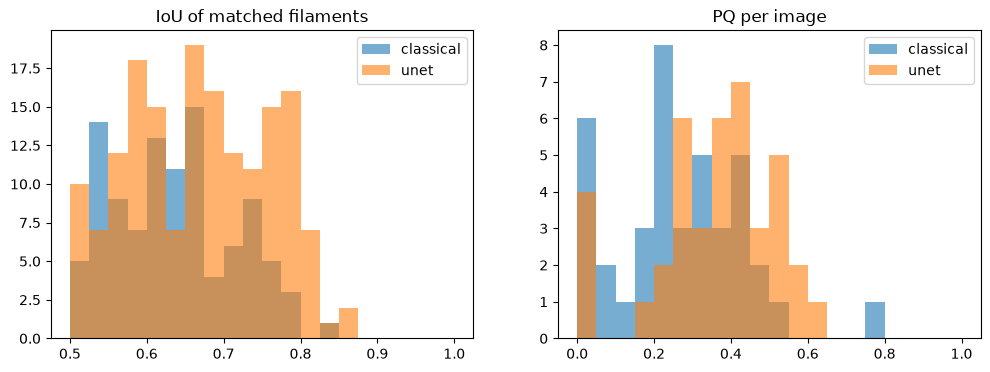

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, sc in [("classical", scores_c)] + ([("unet", scores_u)] if model is not None else []):
    ax[0].hist([v for s in sc for v in s.ious], bins=20, range=(0.5, 1), alpha=0.6, label=name)
    ax[1].hist([s.pq for s in sc if not np.isnan(s.pq)], bins=20, range=(0, 1), alpha=0.6, label=name)
ax[0].set_title("IoU of matched filaments"); ax[1].set_title("PQ per image")
for a in ax: a.legend()

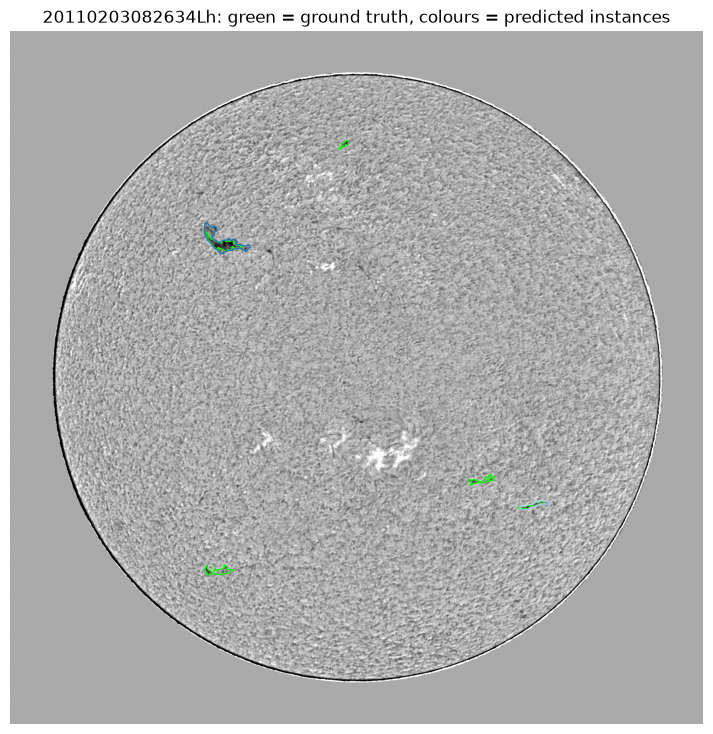

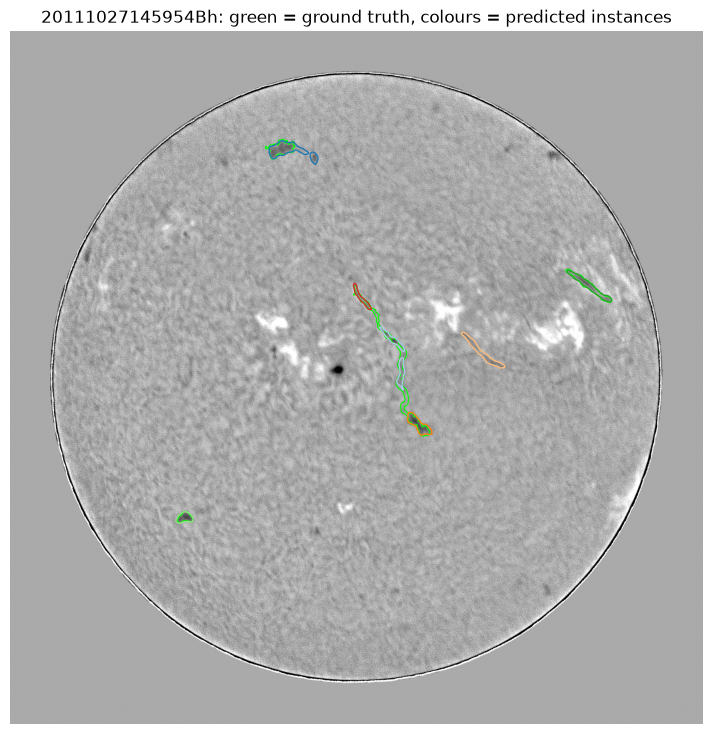

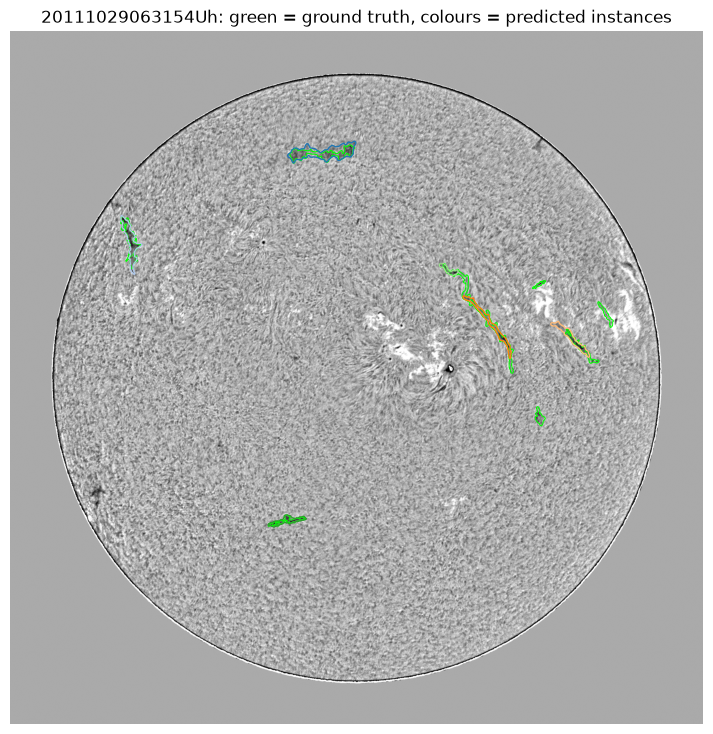

In [10]:
def show(i, method, pp):
    img = read_image(coco.path_of[i]); flat, _ = preprocess(img)
    pred = pipeline.predict_instances(img, method, model, pp, cp)
    plt.figure(figsize=(9, 9)); plt.imshow(flat, cmap="gray", vmin=0.6, vmax=1.2)
    for m in coco.instance_masks(i): plt.contour(m, [0.5], colors="lime", linewidths=0.7)
    cmap = plt.get_cmap("tab20")
    for k, m in enumerate(pred): plt.contour(m, [0.5], colors=[cmap(k % 20)], linewidths=0.9)
    plt.title(f"{image_id_from_path(coco.path_of[i])}: green = ground truth, colours = predicted instances"); plt.axis("off")

for i in val_ids[:3]:
    show(i, METHOD, pp_u if model is not None else pp_c)

## 7. Submission

In [11]:
test_paths = list_images(TEST_DIR)
pp = pp_u if model is not None else pp_c
sub = pipeline.make_submission(test_paths, METHOD, "submission.csv", model=model, pp=pp, cp=cp)
sub.head()

0/180 images


25/180 images


50/180 images


75/180 images


100/180 images


125/180 images


150/180 images


175/180 images


wrote 1370 filaments for 180 images -> submission.csv (14.31 s/image)


,filament_id,segmentation_rle
0,20110120105534Ch_1,ZjfP22no10O1O2N1O1O1O001O000O2O0O1000O1O0100O1...
1,20110120105534Ch_2,W`fi21no13cPNMin17RQNKnn17nPNJSo16kPNKVo1?1N2O...
2,20110130110334Ch_1,b_nd28go14L2O5K2N10O11mPN\Ohn1b0VQNBjn1j0O01O2...
3,20110130110334Ch_2,UXXn1<co13M2N2O2N3M1O2N1O1N2O1N2O2N4M10O107H2N...
4,20110214175414Mh_1,b]Vb23lo13N1O1O001O010O010O010O001O000000000O1...
